<div align="center">

<!-- Judul Laporan -->
<h1><strong>KECERDASAN ARTIFISIAL UNTUK GEOFISIKA</strong></h1>
</ul>
<!-- Logo Universitas -->
<img src="https://www.unhas.ac.id/wp-content/uploads/2022/09/Logo-Resmi-Unhas-1.png" 
     alt="Logo Universitas Hasanuddin" 
     style="width:250px; margin:20px 0;">

<div align="center">

<!-- Penulis -->
<h3>Disusun Oleh:</h3>
<ul style="list-style:none; padding-left:0; line-height:1.8; width:400px;">
  <li style="display:flex; justify-content:space-between;"><span>MILA AYU LESTARI</span><span>(H061241013)</span></li>
</ul>
<br><br>
<!-- Departemen dan Fakultas -->
<p><strong>PROGRAM STUDI GEOFISIKA</strong></p>
<p><strong>FAKULTAS MATEMATIKA DAN ILMU PENGETAHUAN ALAM</strong></p>
<p><strong>UNIVERSITAS HASANUDDIN</strong></p>
<p><strong>MAKASSAR</strong></p>

<!-- Tahun -->
<p><strong>2026</strong></p>

</div>


# R-CAL-002 — Menghitung Anomaly terhadap Baseline
**Case study:** Survei magnetik drone (UAV magnetometer) untuk mendeteksi anomali sumber terpendam

**Sumber recipe:** *AI Cookbook untuk Earth Sciences* (Assagaf, 2026), Bab 10

---
## 1. Permasalahan

**Latar belakang:** Pada sebuah lahan seluas ±200 m × 200 m diduga terdapat benda atau struktur terpendam yang bersifat magnetik, misalnya objek besi, intrusi batuan mafik, atau zona mineralisasi. Survei magnetik darat berjalan lambat dan melelahkan, sehingga dipilih pemetaan dengan drone yang membawa magnetometer (UAV magnetometer): cakupannya cepat, terbang rendah, dan jarak antar titik ukur rapat.

**Masalah data:** Medan magnet total yang terekam drone bukan sinyal murni dari target. Pembacaan sensor merupakan gabungan dari:
- medan regional bumi (latar belakang yang berubah pelan terhadap posisi),
- variasi harian (drift diurnal),
- noise sensor,
- sesekali spike akibat gangguan, dan titik data yang hilang,
- sinyal anomali dari sumber terpendam (yang ingin dicari).

**Tujuan:** Menghitung anomali magnetik sebagai selisih observasi terhadap baseline (recipe R-CAL-002), dengan QC yang tercatat dan aturan baseline yang dinyatakan jelas, lalu memetakan lokasi anomali.

---
## Teori Singkat

**Medan magnet bumi dan anomali magnetik:** Magnetometer mengukur medan magnet total (satuan nanotesla, nT). Medan ini terdiri dari medan utama bumi yang bersifat regional dan medan tambahan dari batuan atau objek di bawah permukaan yang memiliki kontras suseptibilitas magnetik. Bagian tambahan inilah yang disebut anomali magnetik.

Secara umum, anomali adalah selisih observasi terhadap baseline:

$$\Delta B(x,y) = B_{obs}(x,y) - B_{baseline}(x,y)$$

- Anomali **positif**: medan teramati di atas baseline.
- Anomali **negatif**: di bawah baseline.
- Persamaan ini tidak memilih baseline yang benar. **Aturan baseline, jumlah sampel, dan aturan data hilang harus dinyatakan**, karena mengubah baseline dapat mengubah besar bahkan tanda anomali.

**Sumber anomali:** Benda dengan suseptibilitas magnetik tinggi (misalnya mineral magnetit, batuan basa-ultrabasa, atau objek logam besi) termagnetisasi oleh medan bumi dan menghasilkan medan tambahan. Pada kondisi nyata, anomali umumnya berbentuk dipol (pasangan puncak positif dan negatif) yang bentuknya bergantung pada lintang magnetik dan arah magnetisasi. Pada notebook ini anomali disederhanakan sebagai bentuk Gaussian positif agar fokus pada konsep baseline.

**Baseline:** Baseline adalah perkiraan medan "tanpa target". Bentuknya bisa konstanta (misalnya median), tren linier terhadap posisi, atau model regional seperti IGRF. Pemilihan baseline menentukan besar dan bahkan tanda anomali, sehingga aturan baseline dan jumlah sampel yang dipakai harus dicatat.

**Koreksi dan QC pada survei drone:**
- *Variasi harian (diurnal)*: dikoreksi dengan magnetometer base station yang merekam medan terhadap waktu. Pada notebook ini koreksi tersebut tidak dilakukan.
- *Spike dan data hilang*: ditandai dengan flag, tidak dihapus, agar proses dapat ditelusuri.
- *Gangguan dari drone sendiri*: motor, baterai, dan arah terbang (heading) dapat menimbulkan noise, sehingga sensor biasanya dipasang menjauh dari badan drone.

**Jalur terbang:** Data diambil sepanjang jalur paralel (flight line). Jarak antar jalur menentukan resolusi anomali: sumber yang lebih kecil dari jarak antar jalur bisa terlewat.

**Ambang anomali signifikan:** Anomali dianggap signifikan jika melampaui k kali sigma robust:

$$\sigma_{robust} = 1{,}4826 \times \text{median}\left(|\Delta B - \text{median}(\Delta B)|\right)$$

Sigma robust (berbasis MAD) dipilih agar tidak terpengaruh oleh anomali itu sendiri.

**Batas interpretasi:** Anomali magnetik menunjukkan adanya kontras magnetik, bukan identitas sumbernya. Menentukan apakah sumber berupa objek logam, intrusi, atau mineralisasi memerlukan data pendukung seperti geologi permukaan, pengeboran, atau metode geofisika lain.

## 2. Import library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 3. Parameter survei
Semua asumsi dan unit dinyatakan eksplisit di satu tempat.

In [2]:
SEED = 42
N_LINES = 20             # jumlah jalur terbang (arah Utara-Selatan)
LINE_SPACING = 10.0      # jarak antar jalur [m]
N_PER_LINE = 100         # titik ukur per jalur
POINT_SPACING = 2.0      # jarak antar titik sepanjang jalur [m]

B_REGIONAL = 45000.0     # medan magnet total regional [nT]
REGIONAL_GRAD_E = 0.005  # gradien regional ke Timur [nT/m]
NOISE_SD = 1.5           # noise sensor [nT]
DIURNAL_AMP = 8.0        # amplitudo variasi harian [nT]

SOURCE_X, SOURCE_Y = 100.0, 100.0   # posisi sumber anomali [m]
SOURCE_AMP = 120.0       # amplitudo puncak anomali [nT]
SOURCE_WIDTH = 25.0      # lebar anomali (sigma) [m]

MIN_SAMPLE = 30          # minimum sampel valid untuk baseline
ANOMALY_THRESHOLD = 3    # ambang anomali signifikan (kelipatan sigma robust)

rng = np.random.default_rng(SEED)

## 4. Membangkitkan data sintetik
Medan teramati = regional + anomali Gaussian + drift harian + noise.

In [3]:
x_lines = np.arange(N_LINES) * LINE_SPACING
y_pts = np.arange(N_PER_LINE) * POINT_SPACING
X, Y = np.meshgrid(x_lines, y_pts, indexing="ij")

regional = B_REGIONAL + REGIONAL_GRAD_E * X
source = SOURCE_AMP * np.exp(-((X - SOURCE_X)**2 + (Y - SOURCE_Y)**2) / (2 * SOURCE_WIDTH**2))
t = np.arange(N_LINES * N_PER_LINE).reshape(N_LINES, N_PER_LINE)
diurnal = DIURNAL_AMP * np.sin(2 * np.pi * t / t.size)
noise = rng.normal(0, NOISE_SD, X.shape)

B_obs = regional + source + diurnal + noise

df = pd.DataFrame({
    "line": np.repeat(np.arange(N_LINES), N_PER_LINE),
    "x_m": X.ravel(),
    "y_m": Y.ravel(),
    "t_index": t.ravel(),
    "B_total_nT": B_obs.ravel(),
})
df.head()

,line,x_m,y_m,t_index,B_total_nT
0,0,0.0,0.0,0,45000.457089
1,0,0.0,2.0,1,44998.465175
2,0,0.0,4.0,2,45001.175967
3,0,0.0,6.0,3,45001.486278
4,0,0.0,8.0,4,44997.174022


### 4b. Menyuntikkan kerusakan data (untuk menguji QC)
Ditambahkan 40 titik hilang (NaN) dan 5 spike agar aturan *missing-data* dan QC benar-benar diuji.

In [4]:
bad_idx = rng.choice(len(df), size=40, replace=False)
df.loc[bad_idx, "B_total_nT"] = np.nan
df.loc[rng.choice(len(df), size=5, replace=False), "B_total_nT"] += 400

print("Jumlah baris:", len(df))
print("NaN         :", df["B_total_nT"].isna().sum())

Jumlah baris: 2000
NaN         : 40


## 5. QC non-destruktif
Data **tidak dihapus**; setiap aturan disimpan sebagai kolom flag.

Spike dideteksi dengan **median bergerak sepanjang jalur** (window 7 titik), sehingga anomali geologi yang lebar tidak salah ditandai sebagai spike.

In [5]:
df["flag_missing"] = df["B_total_nT"].isna()

roll_med = (df.groupby("line")["B_total_nT"]
              .transform(lambda v: v.rolling(7, center=True, min_periods=3).median()))
resid = df["B_total_nT"] - roll_med
mad = resid.abs().median() * 1.4826
df["flag_spike"] = resid.abs() > 8 * mad

df["valid"] = ~(df["flag_missing"] | df["flag_spike"])

In [6]:
qc = pd.Series({
    "Total titik ukur": len(df),
    "Missing": int(df["flag_missing"].sum()),
    "Spike": int(df["flag_spike"].sum()),
    "Titik valid": int(df["valid"].sum()),
})
qc

Total titik ukur    2000
Missing               40
Spike                  5
Titik valid         1955
dtype: int64

## 6. Baseline
Dua baseline dibandingkan:

- **A. Konstanta** — median seluruh titik valid.
- **B. Tren linier (x, y)** — kuadrat terkecil, dihitung **iteratif**: titik yang menyimpang > 2σ (kandidat anomali) dikeluarkan agar baseline tidak "tertarik" oleh anomali yang ingin dideteksi.

In [7]:
valid = df[df["valid"]]
assert len(valid) >= MIN_SAMPLE, "Sampel valid tidak cukup untuk baseline"

# Baseline A: konstanta
baseline_const = valid["B_total_nT"].median()

# Baseline B: tren linier robust
use = np.ones(len(valid), dtype=bool)
A_all = np.c_[np.ones(len(valid)), valid["x_m"], valid["y_m"]]
y_all = valid["B_total_nT"].values
for _ in range(5):
    coef, *_ = np.linalg.lstsq(A_all[use], y_all[use], rcond=None)
    r = y_all - A_all @ coef
    use = np.abs(r) < 2 * np.std(r[use])
n_baseline = int(use.sum())

df["baseline_trend_nT"] = coef[0] + coef[1] * df["x_m"] + coef[2] * df["y_m"]

In [8]:
baseline_table = pd.DataFrame({
    "baseline": ["Konstanta (median)", "Tren linier (x,y)"],
    "n_sampel": [len(valid), n_baseline],
    "parameter": [f"{baseline_const:.2f} nT",
                  f"c0={coef[0]:.2f}, cx={coef[1]:.4f}, cy={coef[2]:.4f}"],
})
baseline_table

,baseline,n_sampel,parameter
0,Konstanta (median),1955,45004.90 nT
1,"Tren linier (x,y)",1463,"c0=45007.65, cx=-0.0605, cy=0.0006"


## 7. Menghitung anomali
$x' = x - \text{baseline}$ untuk kedua baseline.

In [9]:
df["anom_const_nT"] = df["B_total_nT"] - baseline_const
df["anom_trend_nT"] = df["B_total_nT"] - df["baseline_trend_nT"]
df[["x_m", "y_m", "B_total_nT", "anom_const_nT", "anom_trend_nT"]].dropna().head()

,x_m,y_m,B_total_nT,anom_const_nT,anom_trend_nT
0,0.0,0.0,45000.457089,-4.445313,-7.190738
1,0.0,2.0,44998.465175,-6.437227,-9.183796
2,0.0,4.0,45001.175967,-3.726435,-6.474148
3,0.0,6.0,45001.486278,-3.416123,-6.164981
4,0.0,8.0,44997.174022,-7.728380,-10.478382


In [10]:
df.loc[df["valid"], ["anom_const_nT", "anom_trend_nT"]].describe().round(2)

,anom_const_nT,anom_trend_nT
count,1955.00,1955.00
mean,7.17,10.13
std,23.99,23.77
min,-15.28,-10.48
25%,-6.51,-2.21
50%,0.00,1.87
75%,6.87,8.56
max,114.64,117.89


## 8. Anomali signifikan
Ambang memakai sigma robust (MAD) pada titik valid, bukan standar deviasi biasa, agar tidak terpengaruh anomali itu sendiri.

In [11]:
a = df.loc[df["valid"], "anom_trend_nT"]
sig = (a - a.median()).abs().median() * 1.4826
df["anom_significant"] = df["valid"] & (df["anom_trend_nT"] > ANOMALY_THRESHOLD * sig)
sig_pts = df[df["anom_significant"]]

print(f"Sigma robust (MAD)      : {sig:.2f} nT")
print(f"Ambang ({ANOMALY_THRESHOLD} sigma)          : {ANOMALY_THRESHOLD*sig:.2f} nT")
print(f"Titik anomali signifikan: {len(sig_pts)}")

Sigma robust (MAD)      : 7.11 nT
Ambang (3 sigma)          : 21.32 nT
Titik anomali signifikan: 314


## 9. Lokasi anomali vs sumber sebenarnya
Karena datanya sintetik, hasil dapat diperiksa terhadap posisi sumber yang diketahui.

In [12]:
peak = df.loc[df.loc[df["valid"], "anom_trend_nT"].idxmax()]
cx = np.average(sig_pts["x_m"], weights=sig_pts["anom_trend_nT"])
cy = np.average(sig_pts["y_m"], weights=sig_pts["anom_trend_nT"])

print(f"Puncak anomali          : {peak['anom_trend_nT']:.1f} nT di (x={peak['x_m']:.0f} m, y={peak['y_m']:.0f} m)")
print(f"Pusat anomali (centroid): x={cx:.1f} m, y={cy:.1f} m")
print(f"Sumber sebenarnya       : x={SOURCE_X:.0f} m, y={SOURCE_Y:.0f} m")

Puncak anomali          : 117.9 nT di (x=100 m, y=98 m)
Pusat anomali (centroid): x=98.0 m, y=100.0 m
Sumber sebenarnya       : x=100 m, y=100 m


## 10. Visualisasi

### 10a. Medan magnet total teramati dan baseline

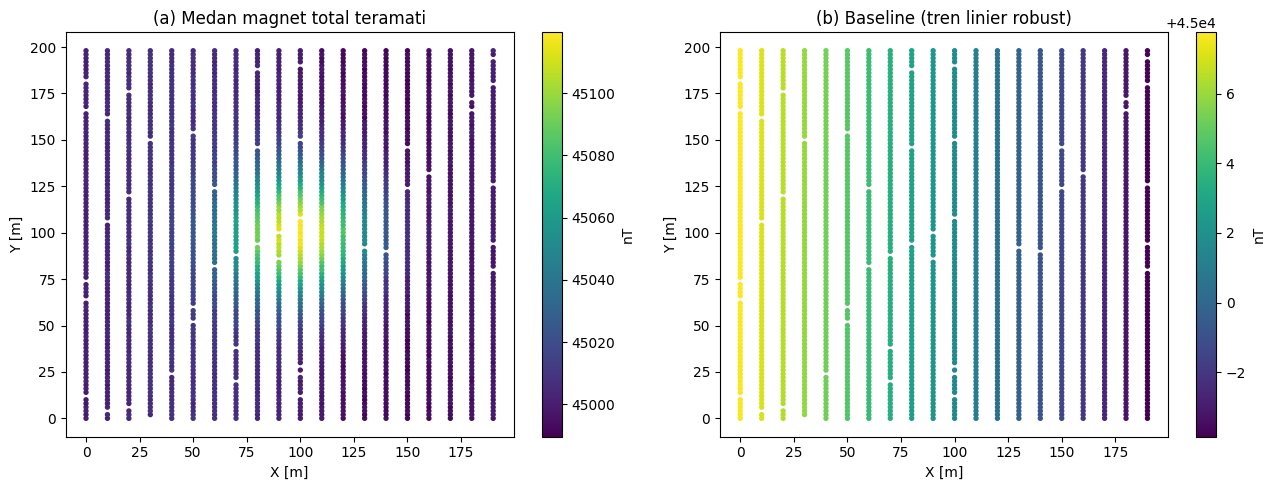

In [13]:
dv = df[df["valid"]]   # plot hanya titik valid

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
sc = ax[0].scatter(dv["x_m"], dv["y_m"], c=dv["B_total_nT"], s=8, cmap="viridis")
ax[0].set(title="(a) Medan magnet total teramati", xlabel="X [m]", ylabel="Y [m]")
plt.colorbar(sc, ax=ax[0], label="nT")

sc = ax[1].scatter(dv["x_m"], dv["y_m"], c=dv["baseline_trend_nT"], s=8, cmap="viridis")
ax[1].set(title="(b) Baseline (tren linier robust)", xlabel="X [m]", ylabel="Y [m]")
plt.colorbar(sc, ax=ax[1], label="nT")
plt.tight_layout()
plt.show()

### 10b. Peta anomali

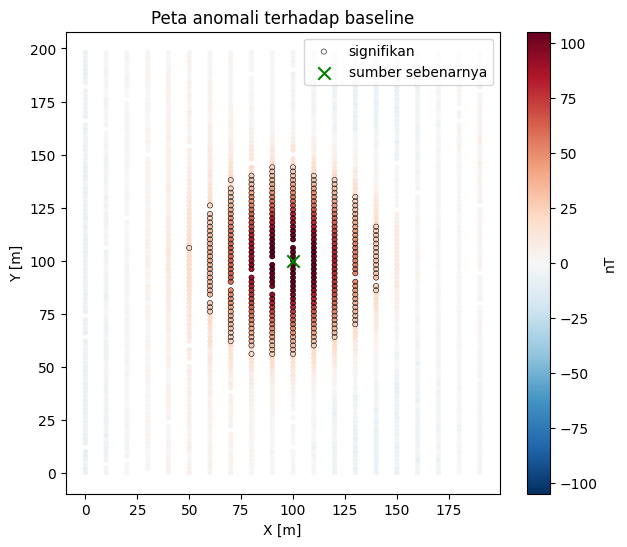

In [14]:
lim = np.nanpercentile(np.abs(dv["anom_trend_nT"]), 99)
fig, ax = plt.subplots(figsize=(7, 6))
sc = ax.scatter(dv["x_m"], dv["y_m"], c=dv["anom_trend_nT"], s=8, cmap="RdBu_r", vmin=-lim, vmax=lim)
ax.scatter(sig_pts["x_m"], sig_pts["y_m"], s=14, facecolors="none", edgecolors="k", linewidths=0.4, label="signifikan")
ax.scatter([SOURCE_X], [SOURCE_Y], marker="x", c="g", s=80, label="sumber sebenarnya")
ax.set(title="Peta anomali terhadap baseline", xlabel="X [m]", ylabel="Y [m]")
ax.legend(loc="upper right")
plt.colorbar(sc, ax=ax, label="nT")
plt.show()

### 10c. Profil jalur yang melewati sumber

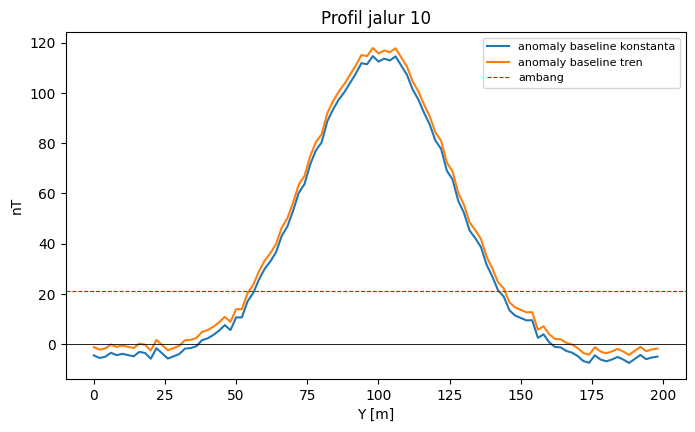

In [15]:
l = int(round(SOURCE_X / LINE_SPACING))
d = dv[dv["line"] == l]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(d["y_m"], d["anom_const_nT"], label="anomaly baseline konstanta")
ax.plot(d["y_m"], d["anom_trend_nT"], label="anomaly baseline tren")
ax.axhline(0, color="k", lw=0.6)
ax.axhline(ANOMALY_THRESHOLD * sig, color="r", ls="--", lw=0.8, label="ambang")
ax.set(title=f"Profil jalur {l}", xlabel="Y [m]", ylabel="nT")
ax.legend(fontsize=8)
plt.show()

## 11. Interpretasi dan batasan
**Temuan (faktual)**
- Anomali positif terpusat dekat (100, 100) m, sesuai posisi sumber sintetik.
- Titik hilang dan spike ditandai flag, tidak dihapus, sehingga proses dapat ditelusuri.

**Batasan**
- Data sintetik; hasil ini bukan klaim tentang kondisi lapangan nyata.
- Drift harian **tidak dikoreksi** (butuh data base station), sehingga ikut terserap ke baseline tren. Karena itu koefisien tren hasil estimasi berbeda dari gradien regional yang dimasukkan.
- Anomali positif bukan bukti litologi atau objek tertentu; interpretasi perlu data pendukung.

## 11. Kesimpulan

Recipe R-CAL-002 berhasil diterapkan pada studi kasus survei magnetik drone (data sintetik). Anomali dihitung dengan

$$\Delta B(x,y) = B_{obs}(x,y) - B_{baseline}(x,y)$$

1. **Anomali signifikan:** Ada. Dari 1955 titik valid, 314 titik melampaui ambang 3σ robust (21,3 nT) dan mengelompok di satu area.
2. **Lokasi anomali:** Puncak anomali 117,9 nT berada di (100 m; 98 m), dan pusatnya di (98,0 m; 100,0 m), sangat dekat dengan sumber sebenarnya (100 m; 100 m).
3. **Pengaruh baseline:** Pilihan baseline mengubah nilai anomali. Baseline tren linier menyerap sebagian drift harian yang tidak dikoreksi, sehingga aturan baseline harus selalu dinyatakan.

QC non-destruktif menandai 40 titik hilang dan 5 spike tanpa menghapus data, sehingga seluruh proses dapat ditelusuri.

**Keterbatasan:** hasil berasal dari data sintetik dan tanpa koreksi base station. Pada data lapangan, koreksi drift harian, pemodelan regional (misalnya IGRF), dan data geologi pendukung diperlukan sebelum sumber anomali diinterpretasikan.